[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C18/E18-3_TimeSeries_RUL_CORRIGE.ipynb)

# Durée de vie restante d'une flotte de machines

## Le contexte

Cent machines d'une flotte sont suivies cycle par cycle jusqu'à leur défaillance : réglages de charge et de vitesse, température du carter, pression de ligne, vibration, courant du moteur, contamination de l'huile. Le service de maintenance voudrait savoir, à chaque relevé, combien de cycles il reste avant la défaillance d'une machine, pour planifier l'arrêt au bon moment : trop tôt, on jette de la durée de vie ; trop tard, on subit la panne. Les 18 855 relevés de cent machines mènent une étude temporelle complète.

La grandeur à prédire est un nombre de cycles : c'est un problème de régression sur des séries temporelles. La base de test réunit des machines entières, jamais vues : le modèle servira sur des machines neuves, pas sur le futur de machines déjà apprises.

Défi : prédire `Duree_Vie_Restante_Cycles` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est une régression linéaire sur les mesures du relevé, sans mémoire des relevés précédents ; il atteint un R² de 0,783. Deux comparaisons sans apprentissage : la moyenne (-0,001) et une règle d'usure fixe, « la machine dure la durée médiane de l'apprentissage » (0,190). À vous de faire mieux. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-TimeSeries_RUL.xlsx`, dans le dossier `donnees` du dépôt : 18 855 relevés, 10 colonnes. Une ligne est le relevé d'une machine à un cycle.

| Colonne | Signification | Unité |
|---|---|---|
| `ID_Machine` | identifiant de la machine, de 1 à 100 | sans unité |
| `Cycle_Operation_Heures` | heures de fonctionnement cumulées au relevé | h |
| `Reglage_Charge_Nominale_Pourcent` | réglage de la charge | % |
| `Reglage_Vitesse_RPM` | réglage de la vitesse de rotation | tr/min |
| `Temp_Carter_K` | température du carter | K |
| `Pression_Ligne_bar` | pression de la ligne | bar |
| `Vib_RMS_AxeZ_mm_s` | vitesse de vibration efficace selon l'axe Z | mm/s |
| `Courant_Moteur_Amp` | courant du moteur | A |
| `Contamination_Huile_PPM` | particules dans l'huile | ppm |
| `Duree_Vie_Restante_Cycles` | cible : cycles restants avant la défaillance | cycles |

Origine : jeu simulé, cent machines suivies cycle par cycle jusqu'à la défaillance. Il enseigne une méthode, et aucune conclusion de maintenance n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides, le nombre de machines, leur durée de vie et l'ordre des relevés : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-TimeSeries_RUL.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-TimeSeries_RUL.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "Duree_Vie_Restante_Cycles"
print("dimensions :", df.shape)
print("cases vides :", int(df.isna().sum().sum()))
par_machine = df.groupby("ID_Machine")
duree_de_vie = par_machine["Cycle_Operation_Heures"].max()
print("machines :", df["ID_Machine"].nunique(), "; relevés par machine de", int(par_machine.size().min()), "à", int(par_machine.size().max()))
print("durée de vie de", int(duree_de_vie.min()), "à", int(duree_de_vie.max()), "cycles, médiane", int(duree_de_vie.median()))
print("relevés rangés par machine puis par cycle :", bool(par_machine["Cycle_Operation_Heures"].apply(lambda s: s.is_monotonic_increasing).all()))
df.head(3)

dimensions : (18855, 10)
cases vides : 0
machines : 100 ; relevés par machine de 50 à 295
durée de vie de 50 à 295 cycles, médiane 197
relevés rangés par machine puis par cycle : True


,ID_Machine,Cycle_Operation_Heures,Reglage_Charge_Nominale_Pourcent,Reglage_Vitesse_RPM,Temp_Carter_K,Pression_Ligne_bar,Vib_RMS_AxeZ_mm_s,Courant_Moteur_Amp,Contamination_Huile_PPM,Duree_Vie_Restante_Cycles
0,1,1,95.930860,3123.738333,319.411832,4.928791,1.503131,14.529690,52.629322,151
1,1,2,83.668696,2791.132658,319.136279,4.946487,1.327024,15.135191,49.409238,150
2,1,3,95.593820,3211.572356,319.768594,5.148732,1.465277,15.057014,46.219546,149


Lecture du résultat : 18 855 relevés, 100 machines, aucune case vide. Les durées de vie vont de 50 à 295 cycles, avec une médiane de 197 : deux machines d'âge égal n'ont pas la même durée restante. Les relevés sont rangés par machine puis par cycle, ce qui permettra de regarder en arrière sans jamais regarder devant.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-TimeSeries_RUL.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté, machine par machine

Un quart des machines, et non un quart des relevés, est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible : si les relevés d'une même machine se retrouvaient des deux côtés, le modèle reconnaîtrait la machine plutôt que son usure. `GroupShuffleSplit` tire des machines entières ; la graine 42 fixe le tirage et les scores se comparent.

In [2]:
from sklearn.model_selection import GroupShuffleSplit

X = df[["Cycle_Operation_Heures", "Reglage_Charge_Nominale_Pourcent", "Reglage_Vitesse_RPM", "Temp_Carter_K",
        "Pression_Ligne_bar", "Vib_RMS_AxeZ_mm_s", "Courant_Moteur_Amp", "Contamination_Huile_PPM"]]
y = df[cible]
decoupage = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=GRAINE)
position_train, position_test = next(decoupage.split(X, y, groups=df["ID_Machine"]))
X_train, X_test = X.iloc[position_train], X.iloc[position_test]
y_train, y_test = y.iloc[position_train], y.iloc[position_test]
groupes_train = df["ID_Machine"].iloc[position_train]
print("apprentissage :", len(X_train), "relevés,", groupes_train.nunique(), "machines")
print("test :", len(X_test), "relevés,", df["ID_Machine"].iloc[position_test].nunique(), "machines")
print("machines communes aux deux bases :", len(set(groupes_train) & set(df["ID_Machine"].iloc[position_test])))

apprentissage : 14186 relevés, 75 machines
test : 4669 relevés, 25 machines
machines communes aux deux bases : 0


### Étape 3 : explorer l'apprentissage

Deux lectures sur `X_train` et `y_train` : la corrélation de chaque mesure avec la durée restante, et l'évolution de la vibration de trois machines d'apprentissage en fonction du temps qui leur reste. La figure montre comment la vibration de chaque machine évolue vers la défaillance.

Temp_Carter_K                      -0.86
Vib_RMS_AxeZ_mm_s                  -0.84
Pression_Ligne_bar                  0.82
Contamination_Huile_PPM            -0.82
Courant_Moteur_Amp                 -0.81
Cycle_Operation_Heures             -0.64
Reglage_Charge_Nominale_Pourcent    0.01
Reglage_Vitesse_RPM                 0.00


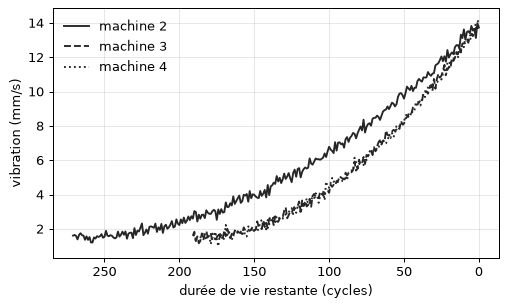

In [3]:
correlations = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print(correlations.round(2).to_string())
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for machine, style in zip(sorted(groupes_train.unique())[:3], ["-", "--", ":"]):
    choix = groupes_train == machine
    ax.plot(y_train[choix], X_train.loc[choix.index[choix], "Vib_RMS_AxeZ_mm_s"], style, color="0.15", label=f"machine {machine}")
ax.set(xlabel="durée de vie restante (cycles)", ylabel="vibration (mm/s)")
ax.invert_xaxis()
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

Lecture du résultat : la mesure la mieux corrélée à la durée restante est `Temp_Carter_K` (-0,86), devant `Vib_RMS_AxeZ_mm_s` (-0,84) ; les réglages de charge et de vitesse n'en disent presque rien. Sur la figure, la vibration de chaque machine monte à mesure que la durée restante diminue, avec une dispersion d'une machine à l'autre : une valeur isolée est ambiguë, une tendance sur plusieurs relevés l'est moins. Le modèle de départ, qui ne voit qu'un relevé à la fois, n'a pas cette information.

### Étape 4 : construire le modèle de départ

Le modèle de départ est une régression linéaire sur les huit mesures du relevé, chacune ramenée à une moyenne nulle et à un écart type de 1. Il apprend sur `X_train` seul. Une règle sans apprentissage le suit : prédire la durée médiane des machines d'apprentissage moins les heures déjà accomplies.

In [4]:
# Solution :
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

preprocessor = StandardScaler()
modele = make_pipeline(preprocessor, LinearRegression())
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

### Étape 5 : mesurer sur la base de test

Le modèle prédit des machines qu'il n'a jamais vues. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en cycles, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE). Deux comparaisons sans apprentissage situent le résultat : la moyenne de l'apprentissage, et la règle de la durée médiane.

In [5]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test)
score_depart = r2_score(y_test, y_pred)
score_temoin = r2_score(y_test, np.full(len(y_test), y_train.mean()))
vie_mediane = (y_train + X_train["Cycle_Operation_Heures"]).groupby(groupes_train).first().median()
score_regle = r2_score(y_test, vie_mediane - X_test["Cycle_Operation_Heures"])
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.1f} cycles")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.1f} cycles")
print(f"R² du témoin (toujours la moyenne de l'apprentissage) : {score_temoin:.3f}")
print(f"R² de la règle (durée médiane {vie_mediane:.0f} cycles moins l'âge) : {score_regle:.3f}")
print(f"prédictions négatives : {(y_pred < 0).sum()} sur {len(y_pred)}")

R² : 0.783
RMSE : 33.3 cycles
MAE : 24.2 cycles
R² du témoin (toujours la moyenne de l'apprentissage) : -0.001
R² de la règle (durée médiane 201 cycles moins l'âge) : 0.190
prédictions négatives : 276 sur 4669


Lecture du résultat : le R² est de 0,783 et l'erreur absolue moyenne de 24,2 cycles, pour une durée restante moyenne de 106 cycles sur la base de test. Le témoin qui répond la moyenne est à -0,001 et la règle de la durée médiane à 0,190 : la règle n'est pas absurde, mais les machines ne vivent pas toutes la même durée. La droite prédit même une durée négative pour 276 relevés sur 4669. C'est ce chiffre, mesuré sur des machines que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : donner de la mémoire au modèle

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première ajoute, pour chaque capteur, sa moyenne sur les 10 derniers relevés de la même machine et l'écart entre cette moyenne et la moyenne depuis le début de la machine : ces variables ne regardent que le passé de la machine, jamais l'avenir, ni une autre machine. Elle compare ensuite, par validation croisée par groupes de machines sur l'apprentissage seul, la droite et un gradient boosting, avec et sans cette mémoire. La seconde mesure le modèle retenu une seule fois sur le test.

In [6]:
# Solution :
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_score

capteurs = ["Temp_Carter_K", "Pression_Ligne_bar", "Vib_RMS_AxeZ_mm_s", "Courant_Moteur_Amp", "Contamination_Huile_PPM"]
passe = df.groupby("ID_Machine")
X_memoire = X.copy()
for capteur in capteurs:
    moyenne10 = passe[capteur].transform(lambda s: s.rolling(10, min_periods=1).mean())
    X_memoire[capteur + "_moy10"] = moyenne10
    X_memoire[capteur + "_ecart"] = moyenne10 - passe[capteur].transform(lambda s: s.expanding().mean())
candidats = {
    "droite sans mémoire (modèle de départ)": (modele, list(X.columns)),
    "droite avec mémoire": (make_pipeline(StandardScaler(), LinearRegression()), list(X_memoire.columns)),
    "gradient boosting sans mémoire": (HistGradientBoostingRegressor(random_state=GRAINE), list(X.columns)),
    "gradient boosting avec mémoire": (HistGradientBoostingRegressor(random_state=GRAINE), list(X_memoire.columns))}
plis = GroupKFold(n_splits=5)
notes_cv = {}
for nom, (candidat, colonnes) in candidats.items():
    notes = cross_val_score(candidat, X_memoire.loc[X_train.index, colonnes], y_train, groups=groupes_train, cv=plis, scoring="r2")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 groupes de machines")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
# Fin de la solution

droite sans mémoire (modèle de départ) : R² 0.798 +/- 0.002 sur 5 groupes de machines
droite avec mémoire : R² 0.840 +/- 0.014 sur 5 groupes de machines
gradient boosting sans mémoire : R² 0.899 +/- 0.005 sur 5 groupes de machines
gradient boosting avec mémoire : R² 0.933 +/- 0.007 sur 5 groupes de machines
modèle retenu par la validation croisée : gradient boosting avec mémoire


In [7]:
# Solution :
from sklearn.base import clone

candidat, colonnes = candidats[nom_retenu]
retenu = clone(candidat).fit(X_memoire.loc[X_train.index, colonnes], y_train)
pred_retenu = retenu.predict(X_memoire.loc[X_test.index, colonnes])
r2_retenu = r2_score(y_test, pred_retenu)
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_retenu:.3f}")
print(f"erreur absolue moyenne : {mean_absolute_error(y_test, pred_retenu):.1f} cycles")
print(f"gain sur le modèle de départ : {r2_retenu - score_depart:+.3f}")
# Fin de la solution

gradient boosting avec mémoire, mesuré une fois sur le test : R² 0.918
erreur absolue moyenne : 9.6 cycles
gain sur le modèle de départ : +0.135


Lecture du résultat : en validation croisée par groupes de machines, la droite sans mémoire atteint 0,798, la droite avec mémoire 0,840, le gradient boosting sans mémoire 0,899 et avec mémoire 0,933 : le modèle retenu est « gradient boosting avec mémoire ». Mesuré une seule fois sur le test, il donne un R² de 0,918, soit 0,135 de plus que le modèle de départ, pour une erreur absolue moyenne de 9,6 cycles. Le gain vient des deux ingrédients : la mémoire des relevés passés et la souplesse du gradient boosting.

## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [8]:
import hashlib

score = r2_score(y_test, modele.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % score)

EMPREINTE_TEST = d2780a282917b086ec7ce2ea90fd9babf768445f7bfc428afa44f43c1dae9e39
SCORE_REFERENCE r2 = 0.783


## Synthèse

1. Sur une flotte, on découpe par machines entières : un quart des machines forme la base de test, sinon le modèle reconnaît la machine au lieu d'apprendre son usure.
2. Un modèle qui ne voit qu'un relevé à la fois atteint 0,783 ; la règle de la durée médiane, sans apprentissage, 0,190.
3. La mémoire (moyenne des 10 derniers relevés, écart à la moyenne depuis le début) ne regarde que le passé de la machine : en validation croisée par groupes, elle fait passer le gradient boosting de 0,899 à 0,933.
4. Mesuré une seule fois sur le test, le modèle retenu donne 0,918. Une durée restante est une estimation : l'erreur moyenne reste de 10 cycles.